In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Define dataset path
file_path = "../data/raw/jobs.json"

# Load JSON dataset
jobs = pd.read_json(file_path)

# Display first five records
jobs.head()

,id,title,company,location,salary_range,workplace_type,employment_type,description
0,1,Machine Learning Engineering Internship - Summer 2026,Viant Technology,"Irvine, CA",$40/hr - $50/hr,Hybrid,Internship,What You’ll Do\n\n\n\nViant is seeking a Machine Learning Engineering Intern to support the deve...
1,2,NVIDIA 2026 Internships: Deep Learning Computer Architecture - US,NVIDIA,"Santa Clara, CA",NaN,NaN,Full-time,"By submitting your resume, you’re expressing interest in one of our 2026 Deep Learning Computer ..."
2,3,Summer 2026 Intern - Undergrad User Research - Slack,Salesforce,"San Francisco, CA",$53/hr - $55/hr,Hybrid,Full-time,"To get the best candidate experience, please consider applying for a maximum of 3 roles within 1..."
3,4,Summer 2026 Engineering Intern,Truveta,Greater Seattle Area,$20/hr,Hybrid,Full-time,Truveta is the world’s first health provider led data platform with a vision of Saving Lives wit...
4,5,Applied AI Engineer (Internship),Fortinet,"Santa Clara, CA",NaN,On-site,Full-time,Job Description\n\nWe’re a cybersecurity company building a next-generation AI-driven operations...


In [4]:
print("Number of rows:", jobs.shape[0])
print("Number of columns:", jobs.shape[1])

Number of rows: 1020
Number of columns: 8


In [5]:
print("Dataset columns:")

for column in jobs.columns:
    print(column)

Dataset columns:
id
title
company
location
salary_range
workplace_type
employment_type
description


In [6]:
jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               1020 non-null   int64
 1   title            1020 non-null   str  
 2   company          1019 non-null   str  
 3   location         1020 non-null   str  
 4   salary_range     620 non-null    str  
 5   workplace_type   826 non-null    str  
 6   employment_type  1017 non-null   str  
 7   description      1020 non-null   str  
dtypes: int64(1), str(7)
memory usage: 4.2 MB


In [7]:
missing_values = jobs.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
id                   0
title                0
company              1
location             0
salary_range       400
workplace_type     194
employment_type      3
description          0
dtype: int64


In [11]:
missing_percentage = (missing_values / len(jobs)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

missing_summary

,Missing Values,Percentage (%)
id,0,0.000000
title,0,0.000000
company,1,0.098039
location,0,0.000000
salary_range,400,39.215686
workplace_type,194,19.019608
employment_type,3,0.294118
description,0,0.000000


In [8]:
print("Duplicate records:", jobs.duplicated().sum())

Duplicate records: 0


In [12]:
print("Duplicate job IDs:", jobs['id'].duplicated().sum())

Duplicate job IDs: 0


In [9]:
jobs.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1020.0,NaN,NaN,NaN,510.5,294.592939,1.0,255.75,510.5,765.25,1020.0
title,1020,675,Software Engineer,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company,1019,587,YO IT Consulting,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,1020,277,United States,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_range,620,424,$20/hr,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
workplace_type,826,3,On-site,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,1017,5,Full-time,807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,1020,939,Work Mode: Remote\n\nEngagement Type: Independent Contractor\n\nSchedule: Full-Time or Part-Time...,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Display three job descriptions
for i in range(3):
    print(f"\nJOB {i + 1}")
    print("=" * 80)
    print("Title:", jobs.iloc[i]['title'])
    print("Company:", jobs.iloc[i]['company'])
    print("Description:")
    print(jobs.iloc[i]['description'])
    print("=" * 80)


JOB 1
Title: Machine Learning Engineering Internship - Summer 2026
Company: Viant Technology
Description:
What You’ll Do



Viant is seeking a Machine Learning Engineering Intern to support the development of data-driven and AI-powered solutions that fuel our programmatic advertising platform. This internship provides hands-on experience working alongside experienced ML engineers on real-world models and systems.

THE DAY-TO-DAY




Assist in developing, testing, and evaluating machine learning models and data pipelines
Work with large datasets to support model training, validation, and analysis
Collaborate with engineering and data teams to integrate ML solutions into production systems
Analyze model performance and help document findings and recommendations
Learn best practices for scalable ML systems and experimentation


GREAT TO HAVE


Currently pursuing a PhD in Computer Science, Engineering, Data Science, or a related field
Strong foundation in Python and data structures
Famili

In [15]:
jobs['workplace_type'].value_counts(dropna=False)

workplace_type
On-site    342
Remote     289
Hybrid     195
NaN        194
Name: count, dtype: int64

In [16]:
jobs['employment_type'].value_counts(dropna=False)

employment_type
Full-time     807
Internship    106
Contract       75
Part-time      24
Temporary       5
NaN             3
Name: count, dtype: int64

In [17]:
jobs['location'].value_counts().head(20)

location
United States                151
New York, NY                  72
San Francisco, CA             66
Chicago, IL                   28
Austin, TX                    27
Dallas, TX                    21
San Jose, CA                  21
Santa Clara, CA               18
Eden Prairie, MN              17
Seattle, WA                   15
Atlanta, GA                   14
New York, United States       13
Sunnyvale, CA                 13
Boston, MA                    12
Houston, TX                   11
California, United States     11
Phoenix, AZ                   11
Irvine, CA                    10
Los Angeles, CA                9
Palo Alto, CA                  9
Name: count, dtype: int64

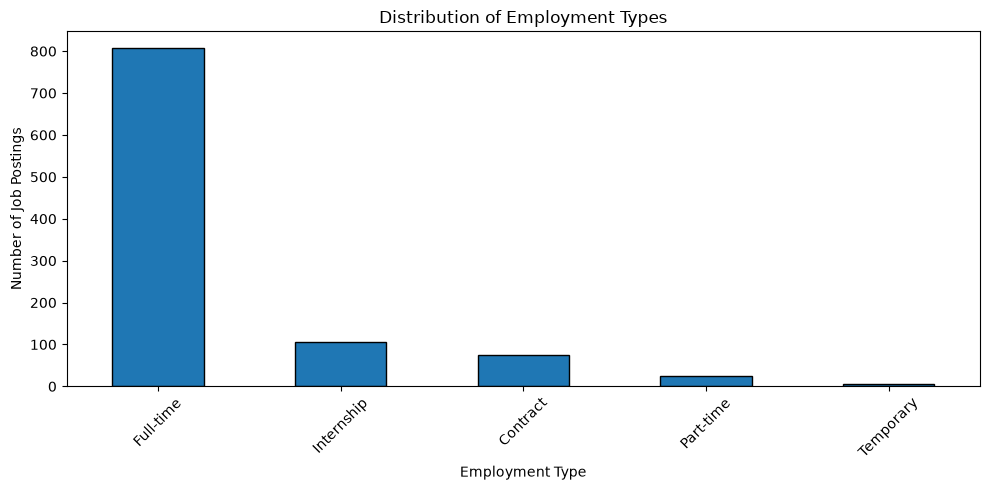

In [18]:
plt.figure(figsize=(10, 5))

jobs['employment_type'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Employment Types')
plt.xlabel('Employment Type')
plt.ylabel('Number of Job Postings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

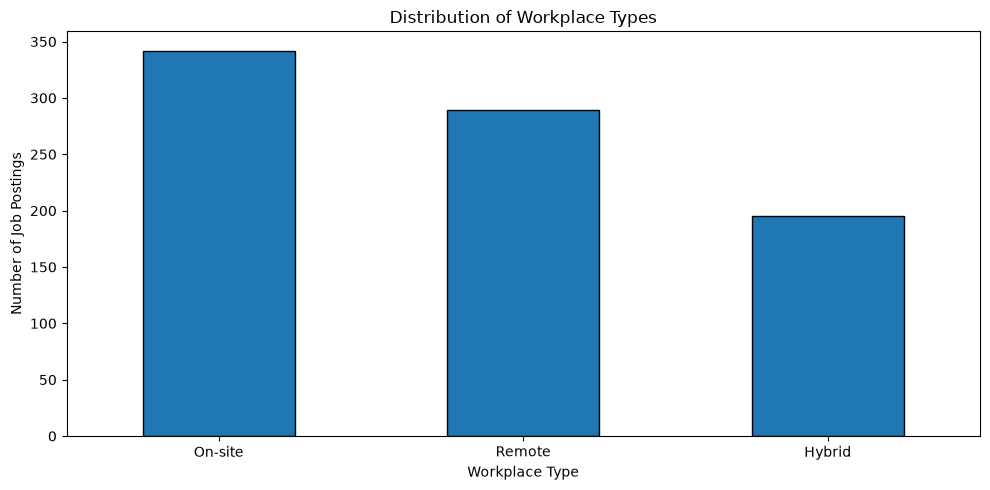

In [19]:
plt.figure(figsize=(10, 5))

jobs['workplace_type'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Workplace Types')
plt.xlabel('Workplace Type')
plt.ylabel('Number of Job Postings')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
os.makedirs("../data/processed", exist_ok=True)

jobs.to_csv(
    "../data/processed/jobs_explored.csv",
    index=False
)

print("Exploration dataset saved successfully!")

Exploration dataset saved successfully!
